# 04 — Question-Only vs. Pretrained BLIP Comparison

## Objective

Evaluate whether incorporating visual information improves Visual Question Answering (VQA) performance compared with using question text alone.

## Models

| Model | Input | Approach |
|---|---|---|
| Question-only baseline | Question text | TF-IDF-based model |
| Pretrained BLIP | Image + question | Pretrained vision-language model |

## Dataset

- **Dataset:** VizWiz VQA
- **Validation examples:** 4,319
- **Answerable:** 2,934
- **Unanswerable:** 1,385

## Evaluation plan

1. Locate saved predictions for both models.
2. Verify matching image identifiers and complete validation coverage.
3. Recalculate VQA-style accuracy with **identical normalization and scoring**.
4. Compare overall, answerable, and unanswerable performance.
5. Inspect paired examples where one model performs better.
6. Save comparison metrics, plots, and example-level results.

## Research question

**Does adding visual information improve VQA accuracy, particularly for answerable questions?**

> Previous pretrained BLIP results: **19.94%** overall, **25.62%** answerable, and **7.91%** unanswerable VQA-style accuracy. These are *preliminary notebook metrics*, not official VizWiz benchmark scores. This notebook recalculates the scores for both models using one consistent implementation.

## 0 — Environment setup

Run in Google Colab. **CPU is sufficient**: we load saved predictions and perform no model inference. Mount your Drive if needed.

In [1]:
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


In [2]:
import json
import re
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

BASE = Path("/content/drive/MyDrive/VQA-Project")
RESULTS = BASE / "results"
VAL_PATH = BASE / "data" / "Annotations" / "val.json"
BLIP_PATH = RESULTS / "blip_pretrained" / "predictions_blip_vqa_base.jsonl"
OUT = RESULTS / "baseline_comparison"

for label, path in [("Project", BASE), ("Annotations", VAL_PATH), ("BLIP predictions", BLIP_PATH)]:
    print(f"{label}: {'FOUND' if path.exists() else 'MISSING'} — {path}")
assert VAL_PATH.is_file() and BLIP_PATH.is_file(), "Check Drive mounting and the paths shown above."

Project: FOUND — /content/drive/MyDrive/VQA-Project
Annotations: FOUND — /content/drive/MyDrive/VQA-Project/data/Annotations/val.json
BLIP predictions: FOUND — /content/drive/MyDrive/VQA-Project/results/blip_pretrained/predictions_blip_vqa_base.jsonl


## 1 — Find question-only predictions

List possible result files. **Do not choose a metrics-only file**: we need a row for each validation image with its predicted answer. Files with only aggregate accuracy are insufficient. If you cannot find a prediction file, stop here and share the printed list; the question-only notebook may need to export its predictions first.

In [3]:
extensions = {".csv", ".jsonl", ".json", ".parquet"}
candidate_paths = sorted(
    (p for p in RESULTS.rglob("*")
     if p.is_file() and p.suffix.lower() in extensions),
    key=lambda p: str(p).lower()
)
print(f"Found {len(candidate_paths)} candidate result files:\n")
for path in candidate_paths:
    print(path.relative_to(BASE))

Found 7 candidate result files:

results/blip_pretrained/error_analysis/all_error_categories.csv
results/blip_pretrained/error_analysis/answerability_category_summary.csv
results/blip_pretrained/error_analysis/manual_error_review.csv
results/blip_pretrained/error_analysis/vqa_category_summary.csv
results/blip_pretrained/predictions_blip_vqa_base.jsonl
results/blip_pretrained/validation_metrics.json
results/blip_pretrained/validation_predictions.csv


### Choose the question-only prediction file

In the cell below, paste the exact path from Step 1 as a string. The placeholder is deliberately `None` to prevent accidentally comparing BLIP against itself or assuming a file exists.

Expected columns are an image identifier (`image`, `image_id`, `filename`, etc.) and a prediction (`prediction`, `predicted_answer`, etc.). The loader will show the columns if they are different.

In [6]:
from pathlib import Path
import pandas as pd

QUESTION_ONLY_PATH = Path(
    "/content/drive/MyDrive/VQA-Project/"
    "results/question_only/validation_predictions.csv"
)

print("File exists:", QUESTION_ONLY_PATH.exists())

pred_df = pd.read_csv(QUESTION_ONLY_PATH)

print("Total predictions:", len(pred_df))
print("Columns:", pred_df.columns.tolist())
display(pred_df.head())

File exists: True
Total predictions: 4319
Columns: ['image', 'question', 'answerable', 'target', 'prediction', 'vqa_style_score', 'top_answer_votes']


,image,question,answerable,target,prediction,vqa_style_score,top_answer_votes
0,VizWiz_val_00000000.jpg,Ok. There is another picture I hope it is a be...,0,unanswerable,unanswerable,1.0,8
1,VizWiz_val_00000001.jpg,Can you tell me what this medicine is please?,1,night time,unanswerable,0.6,5
2,VizWiz_val_00000002.jpg,What is the title of this book?,1,dog years,unanswerable,0.0,9
3,VizWiz_val_00000003.jpg,Which one is the blue one?,1,right,right,1.0,5
4,VizWiz_val_00000004.jpg,What does the arrow say?,0,unanswerable,unanswerable,1.0,8


In [5]:
from pathlib import Path

BASE = Path("/content/drive/MyDrive/VQA-Project")

print("Available notebooks:")
for p in BASE.rglob("*.ipynb"):
    print(p)

Available notebooks:


In [7]:
# REQUIRED: Set this to the existing question-only prediction file shown above.
# Example only (do not assume this path exists):
# QUESTION_ONLY_PATH = RESULTS / "question_only" / "predictions.csv"
QUESTION_ONLY_PATH = (
    RESULTS / "question_only" / "validation_predictions.csv"
)

if QUESTION_ONLY_PATH is None:
    raise ValueError(
        "Set QUESTION_ONLY_PATH to your question-only validation predictions "
        "file after inspecting the listing above. If none exists, share the "
        "listing rather than fabricating predictions."
    )

QUESTION_ONLY_PATH = Path(QUESTION_ONLY_PATH)
print("Question-only file:", QUESTION_ONLY_PATH)
assert QUESTION_ONLY_PATH.is_file()

Question-only file: /content/drive/MyDrive/VQA-Project/results/question_only/validation_predictions.csv


## 2 — Load and validate datasets

We match predictions by image filename rather than by row position, and require exactly the same 4,319 validation images for both models.

In [8]:
def read_table(path):
    path = Path(path)
    suffix = path.suffix.lower()
    if suffix == ".csv":
        return pd.read_csv(path)
    if suffix == ".parquet":
        return pd.read_parquet(path)
    if suffix == ".jsonl":
        with path.open(encoding="utf-8") as f:
            return pd.DataFrame([json.loads(line) for line in f if line.strip()])
    if suffix == ".json":
        with path.open(encoding="utf-8") as f:
            obj = json.load(f)
        if isinstance(obj, list):
            return pd.DataFrame(obj)
        if isinstance(obj, dict):
            for key in ("predictions", "results", "data"):
                if isinstance(obj.get(key), list):
                    return pd.DataFrame(obj[key])
            raise ValueError(f"{path.name}: JSON is not a list of predictions.")
    raise ValueError(f"Unsupported format: {path.suffix}")

def standardize_predictions(raw_df, model_name):
    # Note: answer columns from annotation files are not predictions.
    image_cols = ("image", "image_id", "image_name", "filename", "file_name")
    pred_cols = ("prediction", "predicted_answer", "pred_answer", "pred", "y_pred")
    img_col = next((c for c in image_cols if c in raw_df.columns), None)
    pred_col = next((c for c in pred_cols if c in raw_df.columns), None)
    if img_col is None or pred_col is None:
        raise ValueError(
            f"{model_name}: cannot identify image/prediction columns. "
            f"Available columns: {raw_df.columns.tolist()}"
        )
    out = raw_df[[img_col, pred_col]].rename(
        columns={img_col: "image", pred_col: "prediction"}
    ).copy()
    if out.isna().any().any():
        raise ValueError(f"{model_name}: found missing IDs or predictions")
    out["image"] = out["image"].astype(str).map(lambda x: Path(x).name)
    out["prediction"] = out["prediction"].astype(str)
    if out["image"].duplicated().any():
        raise ValueError(f"{model_name}: duplicate image IDs")
    return out

val_df = read_table(VAL_PATH)
assert {"image", "question", "answers", "answerable"} <= set(val_df.columns)
assert len(val_df) == 4319 and val_df["image"].is_unique
assert set(val_df["answerable"].astype(int).unique()) <= {0, 1}

qo_df = standardize_predictions(read_table(QUESTION_ONLY_PATH), "Question-only")
blip_df = standardize_predictions(read_table(BLIP_PATH), "BLIP")
expected = set(val_df["image"])

for name, frame in [("Question-only", qo_df), ("BLIP", blip_df)]:
    actual = set(frame["image"])
    print(f"{name}: {len(frame)} predictions | "
          f"{len(expected - actual)} missing | {len(actual - expected)} extra")
    if expected != actual:
        print("Missing examples:", sorted(expected - actual)[:5])
        print("Extra examples:", sorted(actual - expected)[:5])
        raise ValueError(f"{name} is not a complete aligned validation set.")

print("All 4,319 validation examples align across both models.")
display(qo_df.head(3))
display(blip_df.head(3))

Question-only: 4319 predictions | 0 missing | 0 extra
BLIP: 4319 predictions | 0 missing | 0 extra
All 4,319 validation examples align across both models.


,image,prediction
0,VizWiz_val_00000000.jpg,unanswerable
1,VizWiz_val_00000001.jpg,unanswerable
2,VizWiz_val_00000002.jpg,unanswerable


,image,prediction
0,VizWiz_val_00000000.jpg,i don ' t know
1,VizWiz_val_00000001.jpg,yes
2,VizWiz_val_00000002.jpg,dog days


## 3 — Recalculate matched VQA-style scores

This reproduces the same simple whitespace/lowercase normalization and leave-one-annotator-out scoring used for your pretrained BLIP evaluation. **Do not substitute the official VizWiz evaluator here without also recalculating both models.**

In [9]:
def normalize_simple(value):
    return re.sub(r"\s+", " ", str(value).strip().lower())

def vqa_style_score(prediction, answers):
    pred = normalize_simple(prediction)
    refs = [normalize_simple(a["answer"]) for a in answers]
    return float(np.mean([
        min(sum(pred == ref for j, ref in enumerate(refs) if j != i) / 3.0, 1.0)
        for i in range(len(refs))
    ]))

comparison_df = (
    val_df.merge(
        qo_df.rename(columns={"prediction": "question_only_prediction"}),
        on="image", how="inner", validate="one_to_one"
    ).merge(
        blip_df.rename(columns={"prediction": "blip_prediction"}),
        on="image", how="inner", validate="one_to_one"
    )
)
assert len(comparison_df) == 4319

for prefix, column in [
    ("question_only", "question_only_prediction"),
    ("blip", "blip_prediction")
]:
    comparison_df[f"{prefix}_score"] = [
        vqa_style_score(p, answers)
        for p, answers in zip(comparison_df[column], comparison_df["answers"])
    ]

comparison_df["score_difference"] = (
    comparison_df["blip_score"] - comparison_df["question_only_score"]
)

print("Recalculated BLIP overall score:", f'{comparison_df["blip_score"].mean():.2%}')
print("Previously recorded BLIP overall score: approximately 19.94%")
if abs(comparison_df["blip_score"].mean() - 0.1994) > 0.002:
    print("WARNING: BLIP score differs from the previous result; inspect data and scoring before interpreting.")

Recalculated BLIP overall score: 19.94%
Previously recorded BLIP overall score: approximately 19.94%


## 4 — Compare performance by subset

A positive **BLIP gain (pp)** means BLIP scored higher than the question-only model; a negative value means the opposite. Scores are preliminary VQA-style scores, not official benchmark scores.

In [10]:
subsets = {
    "Overall": comparison_df,
    "Answerable": comparison_df[comparison_df["answerable"].astype(int) == 1],
    "Unanswerable": comparison_df[comparison_df["answerable"].astype(int) == 0],
}
rows = []
for label, df in subsets.items():
    qo = float(df["question_only_score"].mean())
    blip = float(df["blip_score"].mean())
    rows.append({
        "Subset": label,
        "Examples": len(df),
        "Question-only (%)": round(qo * 100, 2),
        "BLIP (%)": round(blip * 100, 2),
        "BLIP gain (pp)": round((blip - qo) * 100, 2),
    })
results_df = pd.DataFrame(rows)
display(results_df)

,Subset,Examples,Question-only (%),BLIP (%),BLIP gain (pp)
0,Overall,4319,52.55,19.94,-32.61
1,Answerable,2934,32.13,25.62,-6.51
2,Unanswerable,1385,95.83,7.91,-87.92


## 5 — Plot baseline comparison

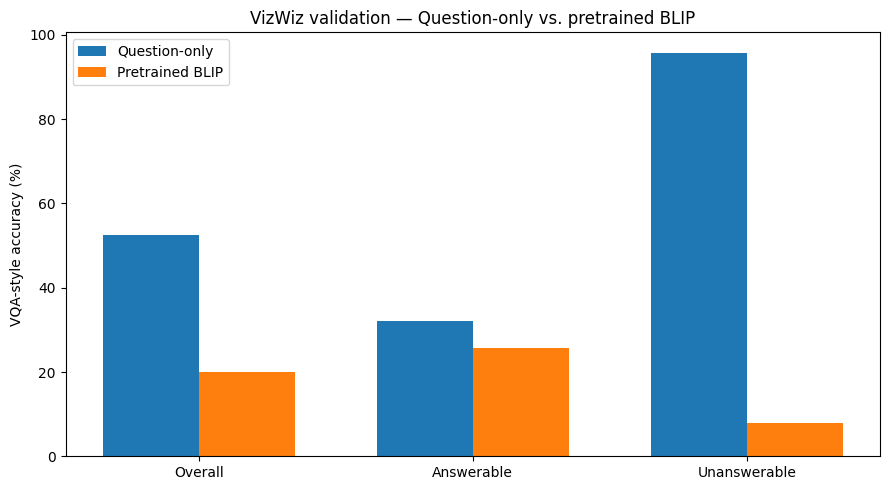

In [11]:
labels = results_df["Subset"].tolist()
x = np.arange(len(labels))
width = 0.35
fig, ax = plt.subplots(figsize=(9, 5))
ax.bar(x - width / 2, results_df["Question-only (%)"], width, label="Question-only")
ax.bar(x + width / 2, results_df["BLIP (%)"], width, label="Pretrained BLIP")
ax.set_xticks(x, labels)
ax.set_ylabel("VQA-style accuracy (%)")
ax.set_title("VizWiz validation — Question-only vs. pretrained BLIP")
ax.legend()
plt.tight_layout()
plt.show()

## 6 — Paired per-example differences

The `winner` field compares the two models on the **same question/image**, rather than comparing unrelated samples. A tie can include cases where both predictions are wrong.

In [12]:
comparison_df["winner"] = np.select(
    [comparison_df["score_difference"] > 1e-9,
     comparison_df["score_difference"] < -1e-9],
    ["BLIP", "Question-only"],
    default="Tie"
)
display(comparison_df["winner"].value_counts().rename_axis("Outcome").reset_index(name="Count"))

columns = [
    "image", "question", "answerable",
    "question_only_prediction", "blip_prediction",
    "question_only_score", "blip_score", "score_difference"
]
print("10 largest BLIP improvements:")
display(comparison_df.nlargest(10, "score_difference")[columns])
print("10 largest question-only improvements:")
display(comparison_df.nsmallest(10, "score_difference")[columns])

,Outcome,Count
0,Question-only,2416
1,Tie,1202
2,BLIP,701


10 largest BLIP improvements:


,image,question,answerable,question_only_prediction,blip_prediction,question_only_score,blip_score,score_difference
11,VizWiz_val_00000011.jpg,What color is this,1,grey,white,0.0,1.0,1.0
28,VizWiz_val_00000028.jpg,Is this a woman?>,1,no,yes,0.0,1.0,1.0
37,VizWiz_val_00000037.jpg,"Hi, I just wanted to confirm that these are in...",1,unanswerable,yes,0.0,1.0,1.0
84,VizWiz_val_00000084.jpg,IS there a picture on this tv screen?,1,no,yes,0.0,1.0,1.0
263,VizWiz_val_00000263.jpg,What color is this?,1,grey,purple,0.0,1.0,1.0
266,VizWiz_val_00000266.jpg,What color is this paper?,1,unanswerable,white,0.0,1.0,1.0
318,VizWiz_val_00000318.jpg,Is my computer screen lit up?,1,unanswerable,yes,0.0,1.0,1.0
394,VizWiz_val_00000394.jpg,What is this?,1,unanswerable,fire hydrant,0.0,1.0,1.0
458,VizWiz_val_00000458.jpg,Is it a mobile?,1,unanswerable,no,0.0,1.0,1.0
541,VizWiz_val_00000541.jpg,What color is this band?,1,silver,gold,0.0,1.0,1.0


10 largest question-only improvements:


,image,question,answerable,question_only_prediction,blip_prediction,question_only_score,blip_score,score_difference
0,VizWiz_val_00000000.jpg,Ok. There is another picture I hope it is a be...,0,unanswerable,i don ' t know,1.0,0.0,-1.0
3,VizWiz_val_00000003.jpg,Which one is the blue one?,1,right,left,1.0,0.0,-1.0
4,VizWiz_val_00000004.jpg,What does the arrow say?,0,unanswerable,7 seconds,1.0,0.0,-1.0
6,VizWiz_val_00000006.jpg,What is seen on the laptop screen? What is see...,0,unanswerable,reflection,1.0,0.0,-1.0
10,VizWiz_val_00000010.jpg,What about the signery.,0,unanswerable,no idea,1.0,0.0,-1.0
12,VizWiz_val_00000012.jpg,This piece of mail for and where is it from?,0,unanswerable,united states,1.0,0.0,-1.0
14,VizWiz_val_00000014.jpg,What does my eye look like?,0,unanswerable,closed,1.0,0.0,-1.0
16,VizWiz_val_00000016.jpg,What is this?,1,unanswerable,pastry,1.0,0.0,-1.0
19,VizWiz_val_00000019.jpg,What is the tag number?,0,unanswerable,0,1.0,0.0,-1.0
20,VizWiz_val_00000020.jpg,What does this sign say?,0,unanswerable,no parking,1.0,0.0,-1.0


## 7 — Optional: inspect paired examples visually

For a stronger claim that images help, manually inspect the image for a few cases with large positive/negative score differences. This cell only displays examples; it does not infer error causes automatically.

Image: VizWiz_val_00000011.jpg
Question: What color is this
Question-only: grey (0.00)
BLIP: white (1.00)
Annotators: [('white', 8), ('light purple', 2)]


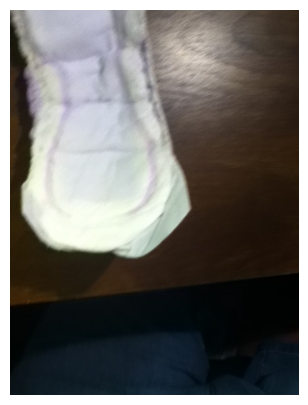

Image: VizWiz_val_00000028.jpg
Question: Is this a woman?>
Question-only: no (0.00)
BLIP: yes (1.00)
Annotators: [('yes', 7), ('unanswerable', 3)]


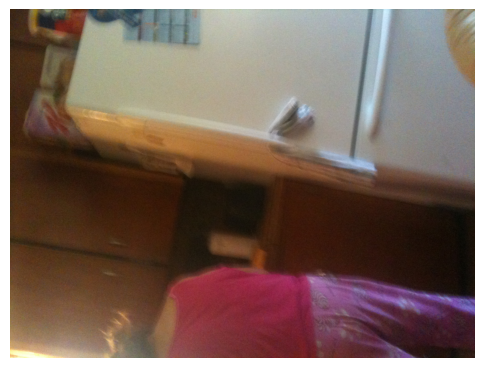

Image: VizWiz_val_00000037.jpg
Question: Hi, I just wanted to confirm that these are indeed pork chops. Any other information that is clear would be appreciated. Thank you.
Question-only: unanswerable (0.00)
BLIP: yes (1.00)
Annotators: [('yes', 7), ('yes kirkland signature pork chops', 1), ('yes porkchops', 1), ('yes loin chops', 1)]


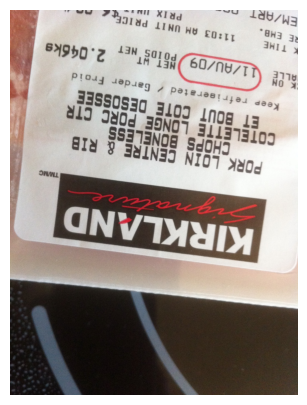

Image: VizWiz_val_00000084.jpg
Question: IS there a picture on this tv screen?
Question-only: no (0.00)
BLIP: yes (1.00)
Annotators: [('yes', 9), ('windows icon', 1)]


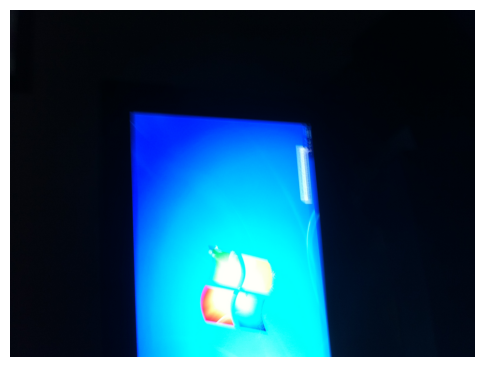

Image: VizWiz_val_00000000.jpg
Question: Ok. There is another picture I hope it is a better one.
Question-only: unanswerable (1.00)
BLIP: i don ' t know (0.00)
Annotators: [('unanswerable', 8), ('cannot repair this computer automatically', 1), ('blank screen', 1)]


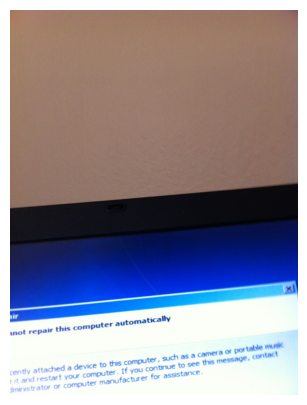

Image: VizWiz_val_00000003.jpg
Question: Which one is the blue one?
Question-only: right (1.00)
BLIP: left (0.00)
Annotators: [('right', 5), ('right 1', 2), ('omni sorb', 1), ('1 on right', 1), ('on right', 1)]


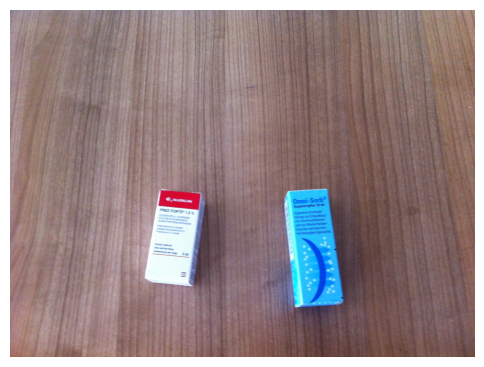

Image: VizWiz_val_00000004.jpg
Question: What does the arrow say?
Question-only: unanswerable (1.00)
BLIP: 7 seconds (0.00)
Annotators: [('unanswerable', 8), ('zoomtext', 2)]


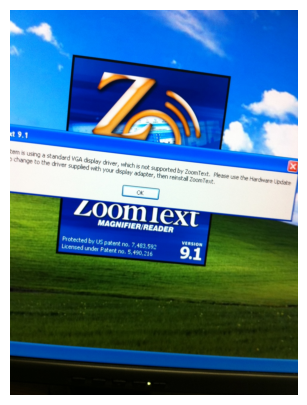

Image: VizWiz_val_00000006.jpg
Question: What is seen on the laptop screen? What is seen on the laptop screen?
Question-only: unanswerable (1.00)
BLIP: reflection (0.00)
Annotators: [('unanswerable', 10)]


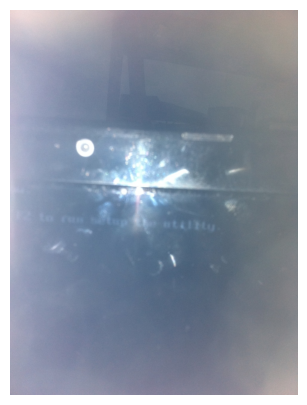

In [13]:
from PIL import Image

IMAGE_DIR = BASE / "data" / "val"

def show_paired_examples(winner="BLIP", n=4):
    if winner not in ("BLIP", "Question-only"):
        raise ValueError("winner must be 'BLIP' or 'Question-only'")
    subset = comparison_df[comparison_df["winner"] == winner]
    subset = (
        subset.nlargest(n, "score_difference")
        if winner == "BLIP"
        else subset.nsmallest(n, "score_difference")
    )
    for _, row in subset.iterrows():
        print("=" * 65)
        print("Image:", row["image"])
        print("Question:", row["question"])
        print("Question-only:", row["question_only_prediction"],
              f'({row["question_only_score"]:.2f})')
        print("BLIP:", row["blip_prediction"], f'({row["blip_score"]:.2f})')
        print("Annotators:", Counter(a["answer"] for a in row["answers"]).most_common(5))
        path = IMAGE_DIR / row["image"]
        if path.is_file():
            with Image.open(path) as im:
                fig, ax = plt.subplots(figsize=(6, 5))
                ax.imshow(im.convert("RGB"))
                ax.axis("off")
                plt.show()
        else:
            print("Image missing:", path)

show_paired_examples("BLIP", n=4)
show_paired_examples("Question-only", n=4)

## 8 — Save outputs

All files go to `results/baseline_comparison/`. The full record includes both predictions and matched per-example scores for later error analysis.

In [14]:
OUT.mkdir(parents=True, exist_ok=True)

results_df.to_csv(OUT / "baseline_comparison_metrics.csv", index=False)

comparison_df[[
    "image", "question", "answerable",
    "question_only_prediction", "blip_prediction",
    "question_only_score", "blip_score",
    "score_difference", "winner"
]].to_csv(OUT / "baseline_comparison_examples.csv", index=False)

fig, ax = plt.subplots(figsize=(9, 5))
ax.bar(x - width / 2, results_df["Question-only (%)"], width, label="Question-only")
ax.bar(x + width / 2, results_df["BLIP (%)"], width, label="Pretrained BLIP")
ax.set_xticks(x, labels)
ax.set_ylabel("VQA-style accuracy (%)")
ax.set_title("VizWiz validation — Baseline comparison")
ax.legend()
plt.tight_layout()
fig.savefig(OUT / "baseline_comparison_chart.png", dpi=180, bbox_inches="tight")
plt.close(fig)

print("Saved comparison metrics, predictions, and chart in:", OUT)

Saved comparison metrics, predictions, and chart in: /content/drive/MyDrive/VQA-Project/results/baseline_comparison



## 9 — Results and Interpretation

### 9.1 Quantitative Comparison

Both models were evaluated on the same 4,319 VizWiz validation examples using identical VQA-style scoring procedures.

| Subset | Examples | Question-only (%) | BLIP (%) | BLIP Gain (pp) |
|---|---:|---:|---:|---:|
| Overall | 4,319 | 52.55 | 19.94 | -32.61 |
| Answerable | 2,934 | 32.13 | 25.62 | -6.51 |
| Unanswerable | 1,385 | 95.83 | 7.91 | -87.92 |

**Observations:**

- The question-only TF-IDF + LinearSVC baseline outperformed pretrained BLIP across all three subsets.
- The largest performance difference occurred on unanswerable questions (87.92 percentage points).
- On answerable questions, the difference was considerably smaller (6.51 percentage points).
- Pretrained BLIP struggled with the dataset's `unanswerable` response, whereas the question-only model frequently predicted this label.

The question-only model was trained on VizWiz, while BLIP was evaluated without VizWiz-specific fine-tuning. Therefore, these results do not isolate the contribution of visual information.

### 9.2 Per-Example Performance Comparison

To examine differences beyond aggregate accuracy, both models' VQA-style scores were compared for each validation example.

| Outcome | Examples | Percentage |
|---|---:|---:|
| Question-only performed better | 2,416 | 55.94% |
| BLIP performed better | 701 | 16.23% |
| Equal VQA score | 1,202 | 27.83% |
| **Total** | **4,319** | **100%** |

**Observations:**

- The question-only baseline achieved higher scores on 2,416 examples.
- Pretrained BLIP outperformed the question-only baseline on 701 examples.
- Both models received equal scores on 1,202 examples.
- Equal scores do not necessarily imply correct predictions; both models may have received zero credit.

Although question-only performed better overall, BLIP's 701 individual wins suggest that it can provide useful predictions missed by the language-only baseline.

### 9.3 Examples Where BLIP Performed Better

| Question | Question-only | BLIP | Human Reference |
|---|---|---|---|
| What color is this? | grey (0.0) | white (1.0) | white |
| Is this a woman? | no (0.0) | yes (1.0) | yes |
| Are these indeed pork chops? | unanswerable (0.0) | yes (1.0) | yes |
| Is there a picture on this TV screen? | no (0.0) | yes (1.0) | yes |

**Observations:**

- BLIP correctly identified visual attributes such as colour in some examples.
- BLIP successfully answered certain yes/no questions that the question-only model answered incorrectly.
- BLIP sometimes provided correct answers when the question-only model defaulted to `unanswerable`.

These examples suggest that visual input may help BLIP answer questions requiring image-specific information.

### 9.4 Examples Where Question-Only Performed Better

| Question | Question-only | BLIP | Human Reference |
|---|---|---|---|
| Which one is the blue one? | right (1.0) | left (0.0) | right |
| What does the arrow say? | unanswerable (1.0) | 7 seconds (0.0) | unanswerable |
| What is seen on the laptop screen? | unanswerable (1.0) | reflection (0.0) | unanswerable |
| What is this? | unanswerable (1.0) | pastry (0.0) | unanswerable |

**Observations:**

- The question-only baseline frequently received full credit by predicting `unanswerable`.
- BLIP sometimes produced specific answers when the human annotations indicated insufficient information.
- The question-only model occasionally predicted the correct answer without seeing the image, illustrating the influence of dataset-specific language patterns and answer distributions.

### 9.5 Impact of Dataset Bias

The question-only model predicted `unanswerable` for approximately 85.69% of validation examples.

This behaviour contributes substantially to its high overall accuracy, particularly on questions labelled unanswerable.

Consequently, high VQA accuracy does not necessarily indicate strong visual understanding.

The results highlight the importance of comparing models against simple baselines and evaluating answerable and unanswerable questions separately.

### 9.6 Limitations

- The question-only baseline was trained on VizWiz, while BLIP was not fine-tuned on this dataset.
- The comparison therefore does not establish a causal effect of adding visual information.
- Scores use a preliminary VQA-style metric with simple answer normalization rather than the verified official VizWiz evaluation implementation.
- The frequent `unanswerable` label strongly influences aggregate accuracy.
- Exact-answer scoring may penalize semantically similar predictions.
- Individual qualitative examples cannot establish how frequently a specific visual failure occurs.

### 9.7 Conclusion

The question-only TF-IDF + LinearSVC model achieved substantially higher overall VQA-style accuracy than pretrained BLIP (52.55% versus 19.94%).

However, its performance was strongly influenced by frequent predictions of `unanswerable`, demonstrating how dataset answer distributions can produce high evaluation scores without visual understanding.

Pretrained BLIP performed better on 701 individual examples, including several questions requiring colour recognition, object identification, or visual yes/no reasoning.

These results motivate VizWiz-specific BLIP fine-tuning to investigate whether adapting a vision-language model to the dataset can improve answer generation and answerability detection.

## 10 — Next Steps

1. Evaluate a constant `unanswerable` baseline to quantify the effect of answer frequency.
2. Verify accuracy using the official VizWiz evaluation implementation.
3. Fine-tune BLIP on the VizWiz training dataset.
4. Compare pretrained and fine-tuned BLIP using identical validation examples.
5. Analyze whether fine-tuning improves visual grounding and recognition of unanswerable questions.
6. Consolidate the results into the final project report.


In [15]:

# Constant "unanswerable" baseline

comparison_df["constant_prediction"] = "unanswerable"

comparison_df["constant_score"] = [
    vqa_style_score("unanswerable", answers)
    for answers in comparison_df["answers"]
]

subsets = {
    "Overall": comparison_df,
    "Answerable": comparison_df[
        comparison_df["answerable"] == 1
    ],
    "Unanswerable": comparison_df[
        comparison_df["answerable"] == 0
    ]
}

constant_results = []

for name, subset in subsets.items():
    constant_results.append({
        "Subset": name,
        "Examples": len(subset),
        "Constant (%)": round(
            subset["constant_score"].mean() * 100, 2
        ),
        "Question-only (%)": round(
            subset["question_only_score"].mean() * 100, 2
        ),
        "Pretrained BLIP (%)": round(
            subset["blip_score"].mean() * 100, 2
        )
    })

constant_results_df = pd.DataFrame(constant_results)

print("THREE-MODEL BASELINE COMPARISON")
display(constant_results_df)


THREE-MODEL BASELINE COMPARISON


,Subset,Examples,Constant (%),Question-only (%),Pretrained BLIP (%)
0,Overall,4319,52.12,52.55,19.94
1,Answerable,2934,29.52,32.13,25.62
2,Unanswerable,1385,100.00,95.83,7.91


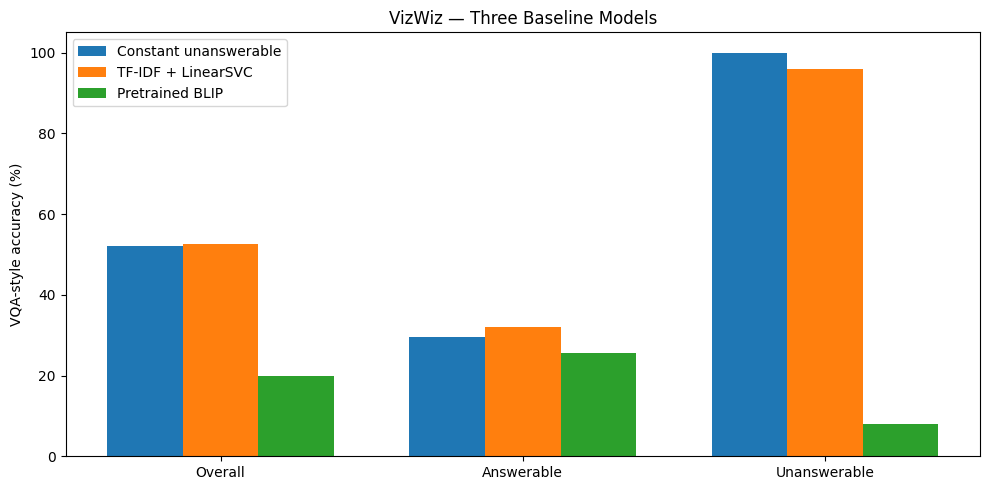

Results saved to: /content/drive/MyDrive/VQA-Project/results/baseline_comparison


In [16]:

import matplotlib.pyplot as plt
import numpy as np

x = np.arange(len(constant_results_df))
width = 0.25

fig, ax = plt.subplots(figsize=(10, 5))

for offset, column, label in [
    (-width, "Constant (%)", "Constant unanswerable"),
    (0, "Question-only (%)", "TF-IDF + LinearSVC"),
    (width, "Pretrained BLIP (%)", "Pretrained BLIP")
]:
    ax.bar(
        x + offset,
        constant_results_df[column],
        width,
        label=label
    )

ax.set_xticks(x)
ax.set_xticklabels(constant_results_df["Subset"])
ax.set_ylabel("VQA-style accuracy (%)")
ax.set_title("VizWiz — Three Baseline Models")
ax.legend()
plt.tight_layout()
plt.show()

# Save outputs
OUT.mkdir(parents=True, exist_ok=True)

constant_results_df.to_csv(
    OUT / "three_model_baseline_metrics.csv",
    index=False
)

fig.savefig(
    OUT / "three_model_baseline_comparison.png",
    dpi=200,
    bbox_inches="tight"
)

plt.close(fig)

print("Results saved to:", OUT)



## Constant Unanswerable Baseline Experiment

### Objective

Determine how much VQA performance can be achieved by
always predicting `unanswerable`, without using either
the question text or the image.

### Models Compared

| Model | Input | Training |
|---|---|---|
| Constant baseline | None | No training |
| Question-only | Question text | TF-IDF + LinearSVC |
| Pretrained BLIP | Image + question | Pretrained, not fine-tuned on VizWiz |

### Evaluation

All three models are evaluated on the same 4,319
VizWiz validation examples using identical VQA-style scoring.

### Results

*To be completed after running the experiment.*

### Research Questions

1. How much accuracy is achievable by predicting
   `unanswerable` for every question?
2. Does the trained question-only model outperform
   this simple constant baseline?
3. To what extent is overall VQA accuracy influenced
   by the frequency of `unanswerable` answers?

### Expected Significance

This experiment helps identify whether high VQA scores
reflect meaningful prediction ability or exploitation
of the dataset's answer distribution.

It also establishes a simple reference for evaluating
future improvements from BLIP fine-tuning.



### Results

| Subset | Constant (%) | Question-only (%) | Pretrained BLIP (%) |
|---|---:|---:|---:|
| Overall | 52.12 | 52.55 | 19.94 |
| Answerable | 29.52 | 32.13 | 25.62 |
| Unanswerable | 100.00 | 95.83 | 7.91 |

### Observations

1. The constant `unanswerable` baseline achieved 52.12% overall
   VQA-style accuracy without examining questions or images.

2. The TF-IDF + LinearSVC question-only baseline achieved 52.55%,
   improving over the constant baseline by only 0.43 percentage points.

3. On answerable examples, the question-only model improved over
   the constant baseline by 2.61 percentage points.

4. The constant baseline achieved 100% on the unanswerable subset,
   illustrating the strong influence of the dataset's answer
   distribution on VQA-style accuracy.

5. Pretrained BLIP achieved 19.94% overall accuracy, but outperformed
   the question-only model on 701 individual examples.

### Interpretation

The results demonstrate that high VQA-style accuracy does not
necessarily indicate strong visual understanding.

A trivial model that always predicts `unanswerable` achieves nearly
the same overall performance as the trained question-only classifier.

The question-only model benefits from the VizWiz answer distribution,
while pretrained BLIP sometimes provides correct image-specific
answers but struggles with unanswerable questions.

Because the question-only model was trained on VizWiz and BLIP was
not fine-tuned on this dataset, this comparison cannot isolate
the causal contribution of image information.

### Conclusion

The constant-baseline experiment reveals a substantial answer-frequency
bias in the evaluation setting.

Future experiments should assess both VQA answer accuracy and
answerability detection, with particular attention to answerable
questions and visually grounded predictions.
